In [261]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.ticker import ScalarFormatter, LogLocator
import country_converter as coco
import os

import requests
import io
import zipfile


#Olympic_df = pd.read_csv("dataset_olympics.csv")
#demo_df = pd.read_csv("world_population_data.csv")
#NOC_df = pd.read_csv("noc_region.csv")

##print(Olympic_df.info())
##print(Olympic_df.head())
##print(Olympic_df.isna().sum())

# Retrieving the datasets by API instead of manual

In [262]:
#  load the datasets (with URL's, found on https://www.kaggle.com/datasets/bhanupratapbiswas/olympic-data/data?select=noc_region.csv and https://www.kaggle.com/datasets/tanishqdublish/world-data-population?select=world_population_data.csv)
#  load the datasets (found on https://www.kaggle.com/datasets/bhanupratapbiswas/olympic-data and https://www.kaggle.com/datasets/tanishqdublish/world-data-population)
# %pip install kagglehub      # eenmalig uitvoeren als het nog niet geïnstalleerd is, daarna kernel herstarten
import kagglehub

# Download de datasets via de Kaggle API (wordt lokaal gecachet, dus maar één keer echt gedownload)
olympic_path = kagglehub.dataset_download("bhanupratapbiswas/olympic-data")
pop_path     = kagglehub.dataset_download("tanishqdublish/world-data-population")

#print(os.listdir(olympic_path))   # check welke bestanden erin zitten
#print(os.listdir(pop_path))

Olympic_df = pd.read_csv(os.path.join(olympic_path, "dataset_olympics.csv"), encoding="latin-1")
NOC_df     = pd.read_csv(os.path.join(olympic_path, "noc_region.csv"))
demo_df    = pd.read_csv(os.path.join(pop_path, "world_population_data.csv"), encoding="latin-1")

In [263]:
##print(Olympic_df.info())                      # checked if the data from the downloaded dataframes is as expected
##print(NOC_df.head())
##print(demo_df.isna().sum())
print(demo_df.columns)

Index(['rank', 'cca3', 'country', 'continent', '2023 population',
       '2022 population', '2020 population', '2015 population',
       '2010 population', '2000 population', '1990 population',
       '1980 population', '1970 population', 'area (kmÂ²)', 'density (kmÂ²)',
       'growth rate', 'world percentage'],
      dtype='str')


Things to be dropped / added:

Name column is not necessary
Winter games, we are intending only to use summer olympics for this case study


Add columns: country (from kaggle's accompanying csv file on NOC code countries)


Additional thought: do we use this dataset or the following one:
https://www.kaggle.com/datasets/heesoo37/120-years-of-olympic-history-athletes-and-results
= original dataset with 134.732 unique athletes

In [264]:
print(len(Olympic_df))                                      # rows in raw dataset
Olympic_df = Olympic_df.drop(columns=["Name"])              # drop the name column
Olympic_df = Olympic_df[Olympic_df["Season"] != "Winter"]   # drop the winter olympic rows
print(len(Olympic_df))                                      # rows after dropping winter games

df = Olympic_df.merge(NOC_df, left_on='NOC', right_on='noc_region', how='left')
df = df.drop(columns=["noc_region"])
print(len(df))                                              # rows after merge, left join so should be equal to the line above

70000
58467
58467


In [265]:
##print(df.isna().sum())                                    # only for 63 results did the noc region not convert into a country name. 

df.loc[df["reg"].isna(), "NOC"].value_counts()              # 55 of those are SGP for singapore, 6 are ROT for Refugee Olympic Team, 1 is TUV for Tuvalu

NOC
SGP    55
ROT     6
UNK     1
TUV     1
Name: count, dtype: int64

In [266]:
noc_to_reg = {
    "SGP": "Singapore",
    "ROT": "Refugee Olympic Team",
    "UNK": "Unknown",
    "TUV": "Tuvalu",
}

mask = df["reg"].isna()                                     # Fill "reg" only where it is missing, using the NOC column as the key
df.loc[mask, "reg"] = df.loc[mask, "NOC"].map(noc_to_reg)

Next step is to prepare the demo_df dataset to insert it into the olympic one. 

- make sure the country names match with the olympic df
- change the year columns into subset rows so that the population numbers can be directly matched to the olympic_dataset rows

In [267]:
demo_df_unmatched = demo_df[~demo_df['country'].isin(df['reg'])]
df_unmatched = df[~df['reg'].isin(demo_df['country'])]


##print(df_unmatched['reg'].value_counts())                             # used to find mismatched country names
##print(demo_df_unmatched['country'].value_counts())

name_map = {
    "United States": "USA",
    "United Kingdom": "UK",
    "Trinidad and Tobago": "Trinidad",
    "United States Virgin Islands": "Virgin Islands, US",
    "Bolivia": "Boliva",                                                # matches the typo in dataset 1
    "Antigua and Barbuda": "Antigua",
    "Republic of the Congo": "Republic of Congo",
    "Saint Kitts and Nevis": "Saint Kitts",
    "DR Congo": "Democratic Republic of the Congo",
    "Saint Vincent and the Grenadines": "Saint Vincent",
    "North Macedonia": "Macedonia",
    "Eswatini": "Swaziland",
    "British Virgin Islands": "Virgin Islands, British",
    "Individual Olympic Athletes": "Other",
    "Refugee Olympic Team": "Other",
    "Unknown": "Other",
}

demo_df["country_clean"] = demo_df["country"].replace(name_map)         # replace country names with a mismatch into a new clean column. Keep the names that match

In [268]:
print(demo_df.head())                                                   # explore the data to see which columns can be removed

   rank cca3        country      continent  2023 population  2022 population  \
0     1  IND          India           Asia       1428627663       1417173173   
1     2  CHN          China           Asia       1425671352       1425887337   
2     3  USA  United States  North America        339996563        338289857   
3     4  IDN      Indonesia           Asia        277534122        275501339   
4     5  PAK       Pakistan           Asia        240485658        235824862   

   2020 population  2015 population  2010 population  2000 population  \
0       1396387127       1322866505       1240613620       1059633675   
1       1424929781       1393715448       1348191368       1264099069   
2        335942003        324607776        311182845        282398554   
3        271857970        259091970        244016173        214072421   
4        227196741        210969298        194454498        154369924   

   1990 population  1980 population  1970 population  area (kmÂ²)  \
0        87

Remove columns rank, country (the pre-filtered one), cca3, world percentage (only applies to 1 moment, not to the splits we will be needing), growth rate. 

In [269]:
demo_df = demo_df.drop(columns=["rank",
                                "cca3",
                                "country",
                                "world percentage",
                                "growth rate"])

print(demo_df.head())

       continent  2023 population  2022 population  2020 population  \
0           Asia       1428627663       1417173173       1396387127   
1           Asia       1425671352       1425887337       1424929781   
2  North America        339996563        338289857        335942003   
3           Asia        277534122        275501339        271857970   
4           Asia        240485658        235824862        227196741   

   2015 population  2010 population  2000 population  1990 population  \
0       1322866505       1240613620       1059633675        870452165   
1       1393715448       1348191368       1264099069       1153704252   
2        324607776        311182845        282398554        248083732   
3        259091970        244016173        214072421        182159874   
4        210969298        194454498        154369924        115414069   

   1980 population  1970 population  area (kmÂ²)  density (kmÂ²) country_clean  
0        696828385        557501301    3287590.0     

change the year columns into subset rows so that the population numbers can be directly matched to the olympic_dataset rows

In [270]:
years = [1970, 1980, 1990, 2000, 2010, 2015, 2020]

parts = []
for y in years:
    pop_col = f'{y} population'
    part = demo_df[['country_clean']].copy()
    part['year'] = y
    part['population'] = demo_df[pop_col]
    part['pct_of_world'] = demo_df[pop_col] / demo_df[pop_col].sum() * 100
    parts.append(part)

long_df = pd.concat(parts, ignore_index=True)
long_df = long_df.sort_values(['country_clean', 'year']).reset_index(drop=True)

#print(long_df.head(10))                                                # exploring result
#print(len(long_df) == len(demo_df) * len(years))
print(long_df.groupby('year')['pct_of_world'].sum())                    # each should be ~100

year
1970    100.0
1980    100.0
1990    100.0
2000    100.0
2010    100.0
2015    100.0
2020    100.0
Name: pct_of_world, dtype: float64


So the long_df is prepared. Now to add a matching year column in the Olympic dataset (and first deal with the missing values in that set)

In [271]:
df['Medal'] = df['Medal'].fillna('None')

df['Age'] = df['Age'].fillna(
    df.groupby(['Sport', 'Sex'])['Age'].transform('median')
)

df['Height'] = df['Height'].fillna(
    df.groupby(['Sport', 'Sex'])['Height'].transform('median')
)

df['Weight'] = df['Weight'].fillna(
    df.groupby(['Sport', 'Sex'])['Weight'].transform('median')
)

df = df.drop(columns=["notes"])                                         # this column got added during the country matching stage. Left it in at that moment, might have been useful then but has to be removed before moving on


In [272]:
print(df.isna().sum())                                      # which columns still have missing values before dropping
print(len(df))
df.dropna(inplace=True)
print(len(df))                                              # rows after dropna
# print(df.isna().sum())                                                # zero missing values at this point

df = df[(df['Year'] >= 1965) & (df['Year'] <= 2022)]                   # only games within reach of the population data (1968-2016)
print(len(df))     # creating the categorical year column to match the demographic dataset


ID          0
Sex         0
Age         0
Height    192
Weight    192
Team        0
NOC         0
Games       0
Year        0
Season      0
City        0
Sport       0
Event       0
Medal       0
reg         0
dtype: int64
58467
58275
39421


time to combine the datasets. 

In [273]:
df_clean = df.copy()
print(len(df_clean))                                        # rows after removing games outside the population years                


39421


In [274]:
olympic_years = sorted(df_clean['Year'].unique())                       # the actual years of the games

rows = []
for country, g in long_df.dropna().groupby('country_clean'):
    g = g.sort_values('year')
    pops = np.interp(olympic_years, g['year'], g['population'])         # linear interpolation between measured years, 1968 gets the 1970 value
    for y, p in zip(olympic_years, pops):
        rows.append((country, y, p))

pop_year_df = pd.DataFrame(rows, columns=['country_clean', 'Year', 'population'])
pop_year_df['pct_of_world'] = (pop_year_df['population']
                               / pop_year_df.groupby('Year')['population'].transform('sum') * 100)

print(pop_year_df.groupby('Year')['pct_of_world'].sum())                # each should be 100

Year
1968    100.0
1972    100.0
1976    100.0
1980    100.0
1984    100.0
1988    100.0
1992    100.0
1996    100.0
2000    100.0
2004    100.0
2008    100.0
2012    100.0
2016    100.0
Name: pct_of_world, dtype: float64


In [275]:
df_merged = df_clean.merge(pop_year_df, left_on=['Year', 'reg'], right_on=['Year', 'country_clean'], how='left')   # merged on the actual year of the games

df_usable = df_merged.loc[~df_merged["country_clean"].isna()]          
print(len(df_merged), len(df_usable))                       # rows before / after removing countries without population data
print(df_merged.loc[df_merged["country_clean"].isna(), "reg"].value_counts().head(10))   # which countries got lost in the merge, which is fine because there is no demografic info


39421 39391
reg
Individual Olympic Athletes    24
Refugee Olympic Team            6
Name: count, dtype: int64


In [276]:
##print(df_usable.info())                                               # exploring dataset with merged data from the 3 original datasets
print(df_usable.head())
##print(df_usable.isna().sum())

   ID Sex   Age  Height  Weight     Team  NOC        Games  Year  Season  \
0   1   M  24.0   180.0    80.0    China  CHN  1992 Summer  1992  Summer   
1   2   M  23.0   170.0    60.0    China  CHN  2012 Summer  2012  Summer   
2  12   M  31.0   172.0    70.0  Finland  FIN  2000 Summer  2000  Summer   
3  13   F  30.0   159.0    55.5  Finland  FIN  1996 Summer  1996  Summer   
4  13   F  34.0   159.0    55.5  Finland  FIN  2000 Summer  2000  Summer   

        City       Sport                         Event Medal      reg  \
0  Barcelona  Basketball   Basketball Men's Basketball  None    China   
1     London        Judo  Judo Men's Extra-Lightweight  None    China   
2     Sydney   Badminton       Badminton Men's Singles  None  Finland   
3    Atlanta     Sailing    Sailing Women's Windsurfer  None  Finland   
4     Sydney     Sailing    Sailing Women's Windsurfer  None  Finland   

  country_clean    population  pct_of_world  
0         China  1.175783e+09     21.452905  
1         Ch

In [277]:
df_usable = df_usable.drop(columns=["Games", "Season", "reg"])          # drop final unnecessary columns  



In [278]:
df_usable["country_clean"] = df_usable["country_clean"].replace("Boliva", "Bolivia")        # fixed typo in the data

df_usable["continent_7"] = coco.convert(df_usable["country_clean"].tolist(), to="continent_7", not_found=np.nan)    # added a column for continent

host_map = {                                                # host country per city, written as in country_clean
    "Mexico City": "Mexico", "Munich": "Germany", "Montreal": "Canada",
    "Moskva": "Russia", "Los Angeles": "USA", "Seoul": "South Korea",
    "Barcelona": "Spain", "Atlanta": "USA", "Sydney": "Australia",
    "Athina": "Greece", "Beijing": "China", "London": "UK",
    "Rio de Janeiro": "Brazil",
}
df_usable["host"] = df_usable["City"].map(host_map) == df_usable["country_clean"]   #  True if the athlete competes in his own country

print(df_usable.loc[df_usable["host"]].groupby("Year")["country_clean"].first())   # check, should give 13 games with 13 host countries

Year
1968         Mexico
1972        Germany
1976         Canada
1980         Russia
1984            USA
1988    South Korea
1992          Spain
1996            USA
2000      Australia
2004         Greece
2008          China
2012             UK
2016         Brazil
Name: country_clean, dtype: str


In [279]:
#print(df_usable.info())                                                    # final check if dataset is finished to be used
print(df_usable.head())
#print(df_usable.isna().sum())

df_usable.to_csv('df_usable_case2.csv', index=False)                               # save to csv

   ID Sex   Age  Height  Weight     Team  NOC  Year       City       Sport  \
0   1   M  24.0   180.0    80.0    China  CHN  1992  Barcelona  Basketball   
1   2   M  23.0   170.0    60.0    China  CHN  2012     London        Judo   
2  12   M  31.0   172.0    70.0  Finland  FIN  2000     Sydney   Badminton   
3  13   F  30.0   159.0    55.5  Finland  FIN  1996    Atlanta     Sailing   
4  13   F  34.0   159.0    55.5  Finland  FIN  2000     Sydney     Sailing   

                          Event Medal country_clean    population  \
0   Basketball Men's Basketball  None         China  1.175783e+09   
1  Judo Men's Extra-Lightweight  None         China  1.366401e+09   
2       Badminton Men's Singles  None       Finland  5.176209e+06   
3    Sailing Women's Windsurfer  None       Finland  5.100343e+06   
4    Sailing Women's Windsurfer  None       Finland  5.176209e+06   

   pct_of_world continent_7   host  
0     21.452905        Asia  False  
1     19.083293        Asia  False  
2    

Below this line there will be no more exploratory preparation of the dataset. Only use of it in analysis to answer our main question

In [280]:
years = sorted(df_usable["Year"].unique())                  # the 13 actual games instead of 6 population years
d = df_usable.drop_duplicates(["ID", "Year"])               #  one row per athlete per games, multiple events count once

# 1) Crosstab: number of participants per continent per year
counts = pd.crosstab(d["continent_7"], d["Year"])           # <- Year

# 2) Relative share: each year's column sums to 100%
share = pd.crosstab(d["continent_7"], d["Year"], normalize="columns") * 100   # <- Year

print(counts)
print(share.round(1))

Year           1968  1972  1976  1980  1984  1988  1992  1996  2000  2004  \
continent_7                                                                 
Africa          103   153    35   166   223   235   237   260   318   284   
Asia            121   159   145   132   269   302   288   354   361   380   
Europe          743  1018   867   869   755  1073  1251  1262  1294  1288   
North America   359   345   386   103   394   366   397   445   420   380   
Oceania          59    78    81    37   127   136   137   151   214   177   
South America   110   117    91    81   168   154   135   205   186   210   

Year           2008  2012  2016  
continent_7                      
Africa          327   313   341  
Asia            386   404   436  
Europe         1240  1259  1224  
North America   416   371   417  
Oceania         190   182   190  
South America   233   238   384  
Year           1968  1972  1976  1980  1984  1988  1992  1996  2000  2004  \
continent_7                       

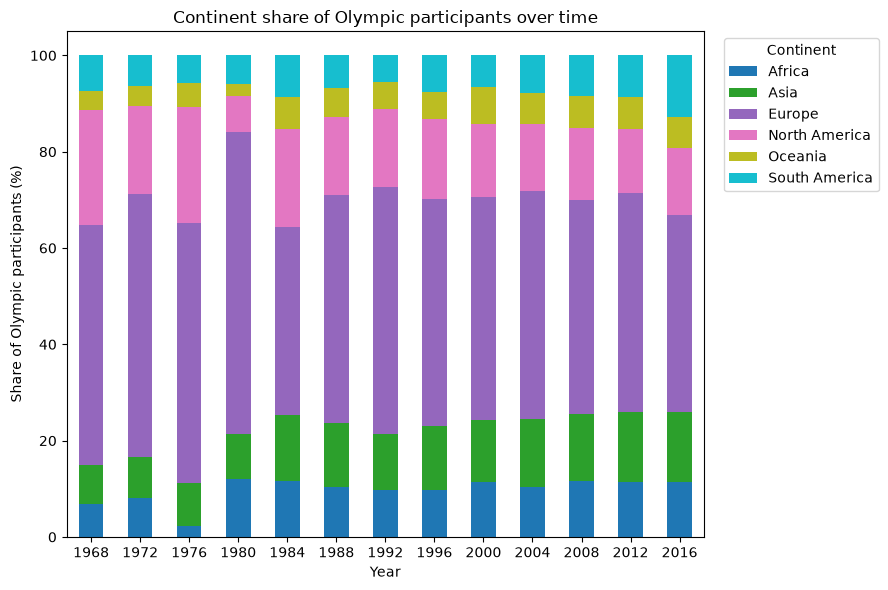

In [281]:
ax = share.T.plot(kind="bar", stacked=True, figsize=(9, 6), colormap="tab10")
ax.set_ylabel("Share of Olympic participants (%)")
ax.set_xlabel("Year")
ax.set_title("Continent share of Olympic participants over time")
ax.legend(title="Continent", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

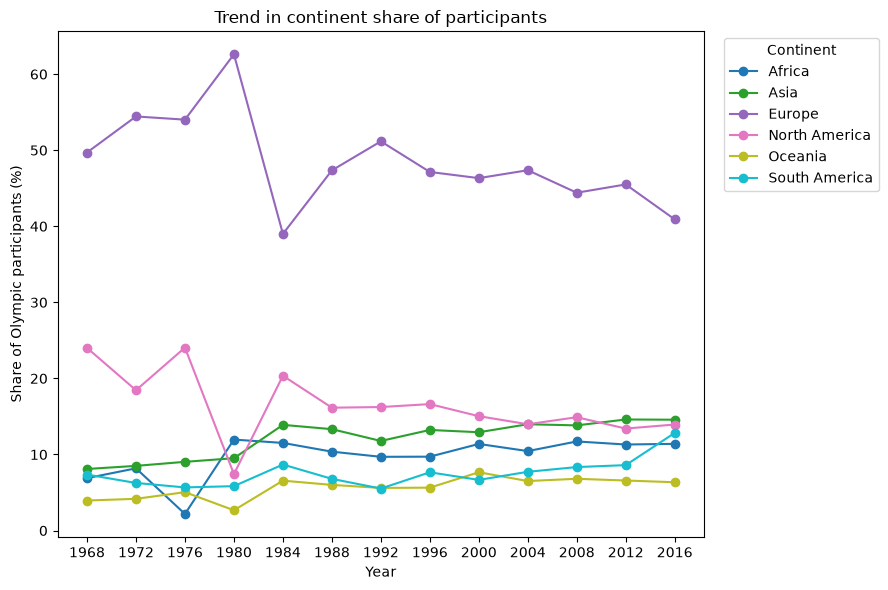

In [282]:
ax = share.T.plot(marker="o", figsize=(9, 6), colormap="tab10")
ax.set_ylabel("Share of Olympic participants (%)")
ax.set_xlabel("Year")
ax.set_xticks(years)
ax.set_title("Trend in continent share of participants")
ax.legend(title="Continent", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

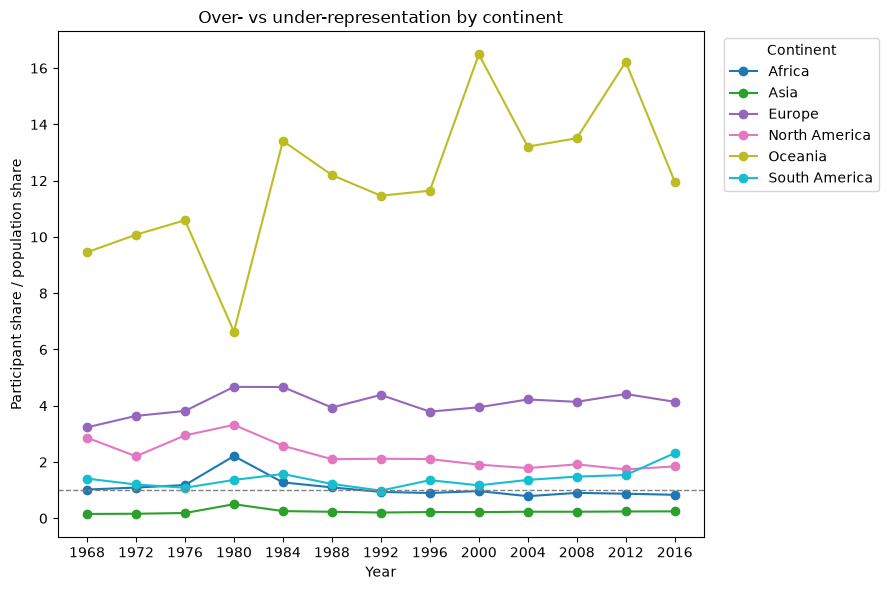

In [283]:
# Continent's share of world population per year
# (sum the country percentages once per country-year, not once per participant)
pop_share = (
    d.drop_duplicates(["Year", "country_clean"])            # one row per country per games
     .groupby(["continent_7", "Year"])["pct_of_world"].sum()   # <- changed: Year
     .unstack("Year")                                       # Year
)

ratio = share / pop_share   # >1 = over-represented, <1 = under-represented

ax = ratio.T.plot(marker="o", figsize=(9, 6), colormap="tab10")
ax.axhline(1, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("Participant share / population share")
ax.set_xlabel("Year")
ax.set_xticks(years)
ax.set_title("Over- vs under-representation by continent")
ax.legend(title="Continent", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [284]:
years = sorted(df_usable["Year"].unique())                               # 13 games instead of 6 groups
d = df_usable
print(df_usable['Year'].value_counts().head(20))

Year
2016    3663
2000    3522
1996    3487
2008    3483
2004    3429
2012    3375
1992    3317
1988    3219
1972    2658
1984    2635
1976    2337
1968    2315
1980    1951
Name: count, dtype: int64


In [285]:
print(df_usable['City'].value_counts().head(20))

City
Rio de Janeiro    3663
Sydney            3522
Atlanta           3487
Beijing           3483
Athina            3429
London            3375
Barcelona         3317
Seoul             3219
Munich            2658
Los Angeles       2635
Montreal          2337
Mexico City       2315
Moskva            1951
Name: count, dtype: int64


In [286]:
print(df_usable.info())

<class 'pandas.DataFrame'>
Index: 39391 entries, 0 to 39420
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             39391 non-null  int64  
 1   Sex            39391 non-null  str    
 2   Age            39391 non-null  float64
 3   Height         39391 non-null  float64
 4   Weight         39391 non-null  float64
 5   Team           39391 non-null  str    
 6   NOC            39391 non-null  str    
 7   Year           39391 non-null  int64  
 8   City           39391 non-null  str    
 9   Sport          39391 non-null  str    
 10  Event          39391 non-null  str    
 11  Medal          39391 non-null  str    
 12  country_clean  39391 non-null  str    
 13  population     39391 non-null  float64
 14  pct_of_world   39391 non-null  float64
 15  continent_7    39391 non-null  str    
 16  host           39391 non-null  bool   
dtypes: bool(1), float64(5), int64(2), str(9)
memory usage: 8.1 MB
None

In [287]:
print(df_usable.duplicated().sum())                         # fully identical rows
print(df_usable.duplicated(["ID", "Year"]).sum())           # same athlete at the same games = more events, not an error
print(df_usable[["Age", "Height", "Weight"]].describe())    # check ranges for strange values 

0
9646
                Age        Height        Weight
count  39391.000000  39391.000000  39391.000000
mean      25.010586    175.836651     70.914942
std        5.721532     10.865372     14.822925
min       12.000000    127.000000     25.000000
25%       21.000000    169.000000     60.000000
50%       24.000000    176.000000     70.000000
75%       28.000000    183.000000     79.000000
max       65.000000    223.000000    214.000000
